In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
import os
import pandas as pd

# --------------------
# inputs / parameters
# --------------------
rod_inputs = {
    "halfrod": "alex/fd_array_halfrod_kinking_seeds/analysis_files",
    "fullrod": "alex/fd_array_fullrod_kinking_seeds/analysis_files",
    "rod40":   "alex/fd_array_40rod_kinking_seeds/analysis_files",
    "rod14":   "alex/fd_array_14rod_kinking_seeds/analysis_files",
}

seeds     = range(1, 6)     # Seed_1 ... Seed_5
k_values  = [0.25]          # extend as needed
r0_values = range(2, 32)    # r0_2 ... r0_31

# --------------------
# helpers
# --------------------
def k_tag_from_value(k: float) -> str:
    return f"{int(round(k * 100)):03d}"  # 0.25 -> "025"

def base_dir(base_analysis: str, seed: int, k_tag: str, r0: int) -> str:
    # analysis_files/Seed_N/K_XXX/r0_N/traps_MD_long/
    return os.path.join(
        base_analysis,
        f"Seed_{seed}",
        f"K_{k_tag}",
        f"r0_{r0}"
    )

def load_obs_dist(path: str) -> pd.DataFrame:
    # obs_dist.dat: step dist force_mag hbond force_energy
    return pd.read_csv(
        path,
        sep=r"\s+",
        header=None,
        names=["step", "dist", "force_mag", "hbond", "force_energy"],
    )

def load_obs_cxstck(path: str) -> pd.DataFrame:
    # obs_cxstck.dat: step cxstck_(31,32) cxstck_(0,85)
    return pd.read_csv(
        path,
        sep=r"\s+",
        header=None,
        names=["step", "cxstck_31_32", "cxstck_0_85"],
    )

# --------------------
# load
# dfs_dist[rod_type][seed][k][r0]   = obs_dist dataframe
# dfs_cxstck["fullrod"][seed][k][r0]= obs_cxstck dataframe (fullrod only)
# --------------------
dfs_dist = {}
dfs_cxstck = {}  # only populated for fullrod

for rod_type, base_analysis in rod_inputs.items():
    dfs_dist[rod_type] = {}
    if rod_type == "fullrod":
        dfs_cxstck[rod_type] = {}

    for seed in seeds:
        dfs_dist[rod_type][seed] = {}
        if rod_type == "fullrod":
            dfs_cxstck[rod_type][seed] = {}

        for k in k_values:
            k_tag = k_tag_from_value(k)
            dfs_dist[rod_type][seed][k] = {}
            if rod_type == "fullrod":
                dfs_cxstck[rod_type][seed][k] = {}

            for r0 in r0_values:
                ddir = base_dir(base_analysis, seed, k_tag, r0)

                # ---- obs_dist.dat for all rod types ----
                dist_path = os.path.join(ddir, "obs_dist.dat")
                if os.path.exists(dist_path):
                    dfs_dist[rod_type][seed][k][r0] = load_obs_dist(dist_path)
                else:
                    print(f"[WARN] Missing obs_dist: {rod_type} seed={seed} k={k_tag} r0={r0} -> {dist_path}")

                # ---- obs_cxstck.dat for fullrod only ----
                if rod_type == "fullrod":
                    cx_path = os.path.join(ddir, "obs_cxstck.dat")
                    if os.path.exists(cx_path):
                        dfs_cxstck["fullrod"][seed][k][r0] = load_obs_cxstck(cx_path)
                    else:
                        print(f"[WARN] Missing obs_cxstck: fullrod seed={seed} k={k_tag} r0={r0} -> {cx_path}")

# Examples:
# dist df for rod40, Seed_2, k=0.25, r0=10
# df_dist = dfs_dist["rod40"][2][0.25][10]
#
# cxstck df for fullrod, Seed_4, k=0.25, r0=10
# df_cx   = dfs_cxstck["fullrod"][4][0.25][10]

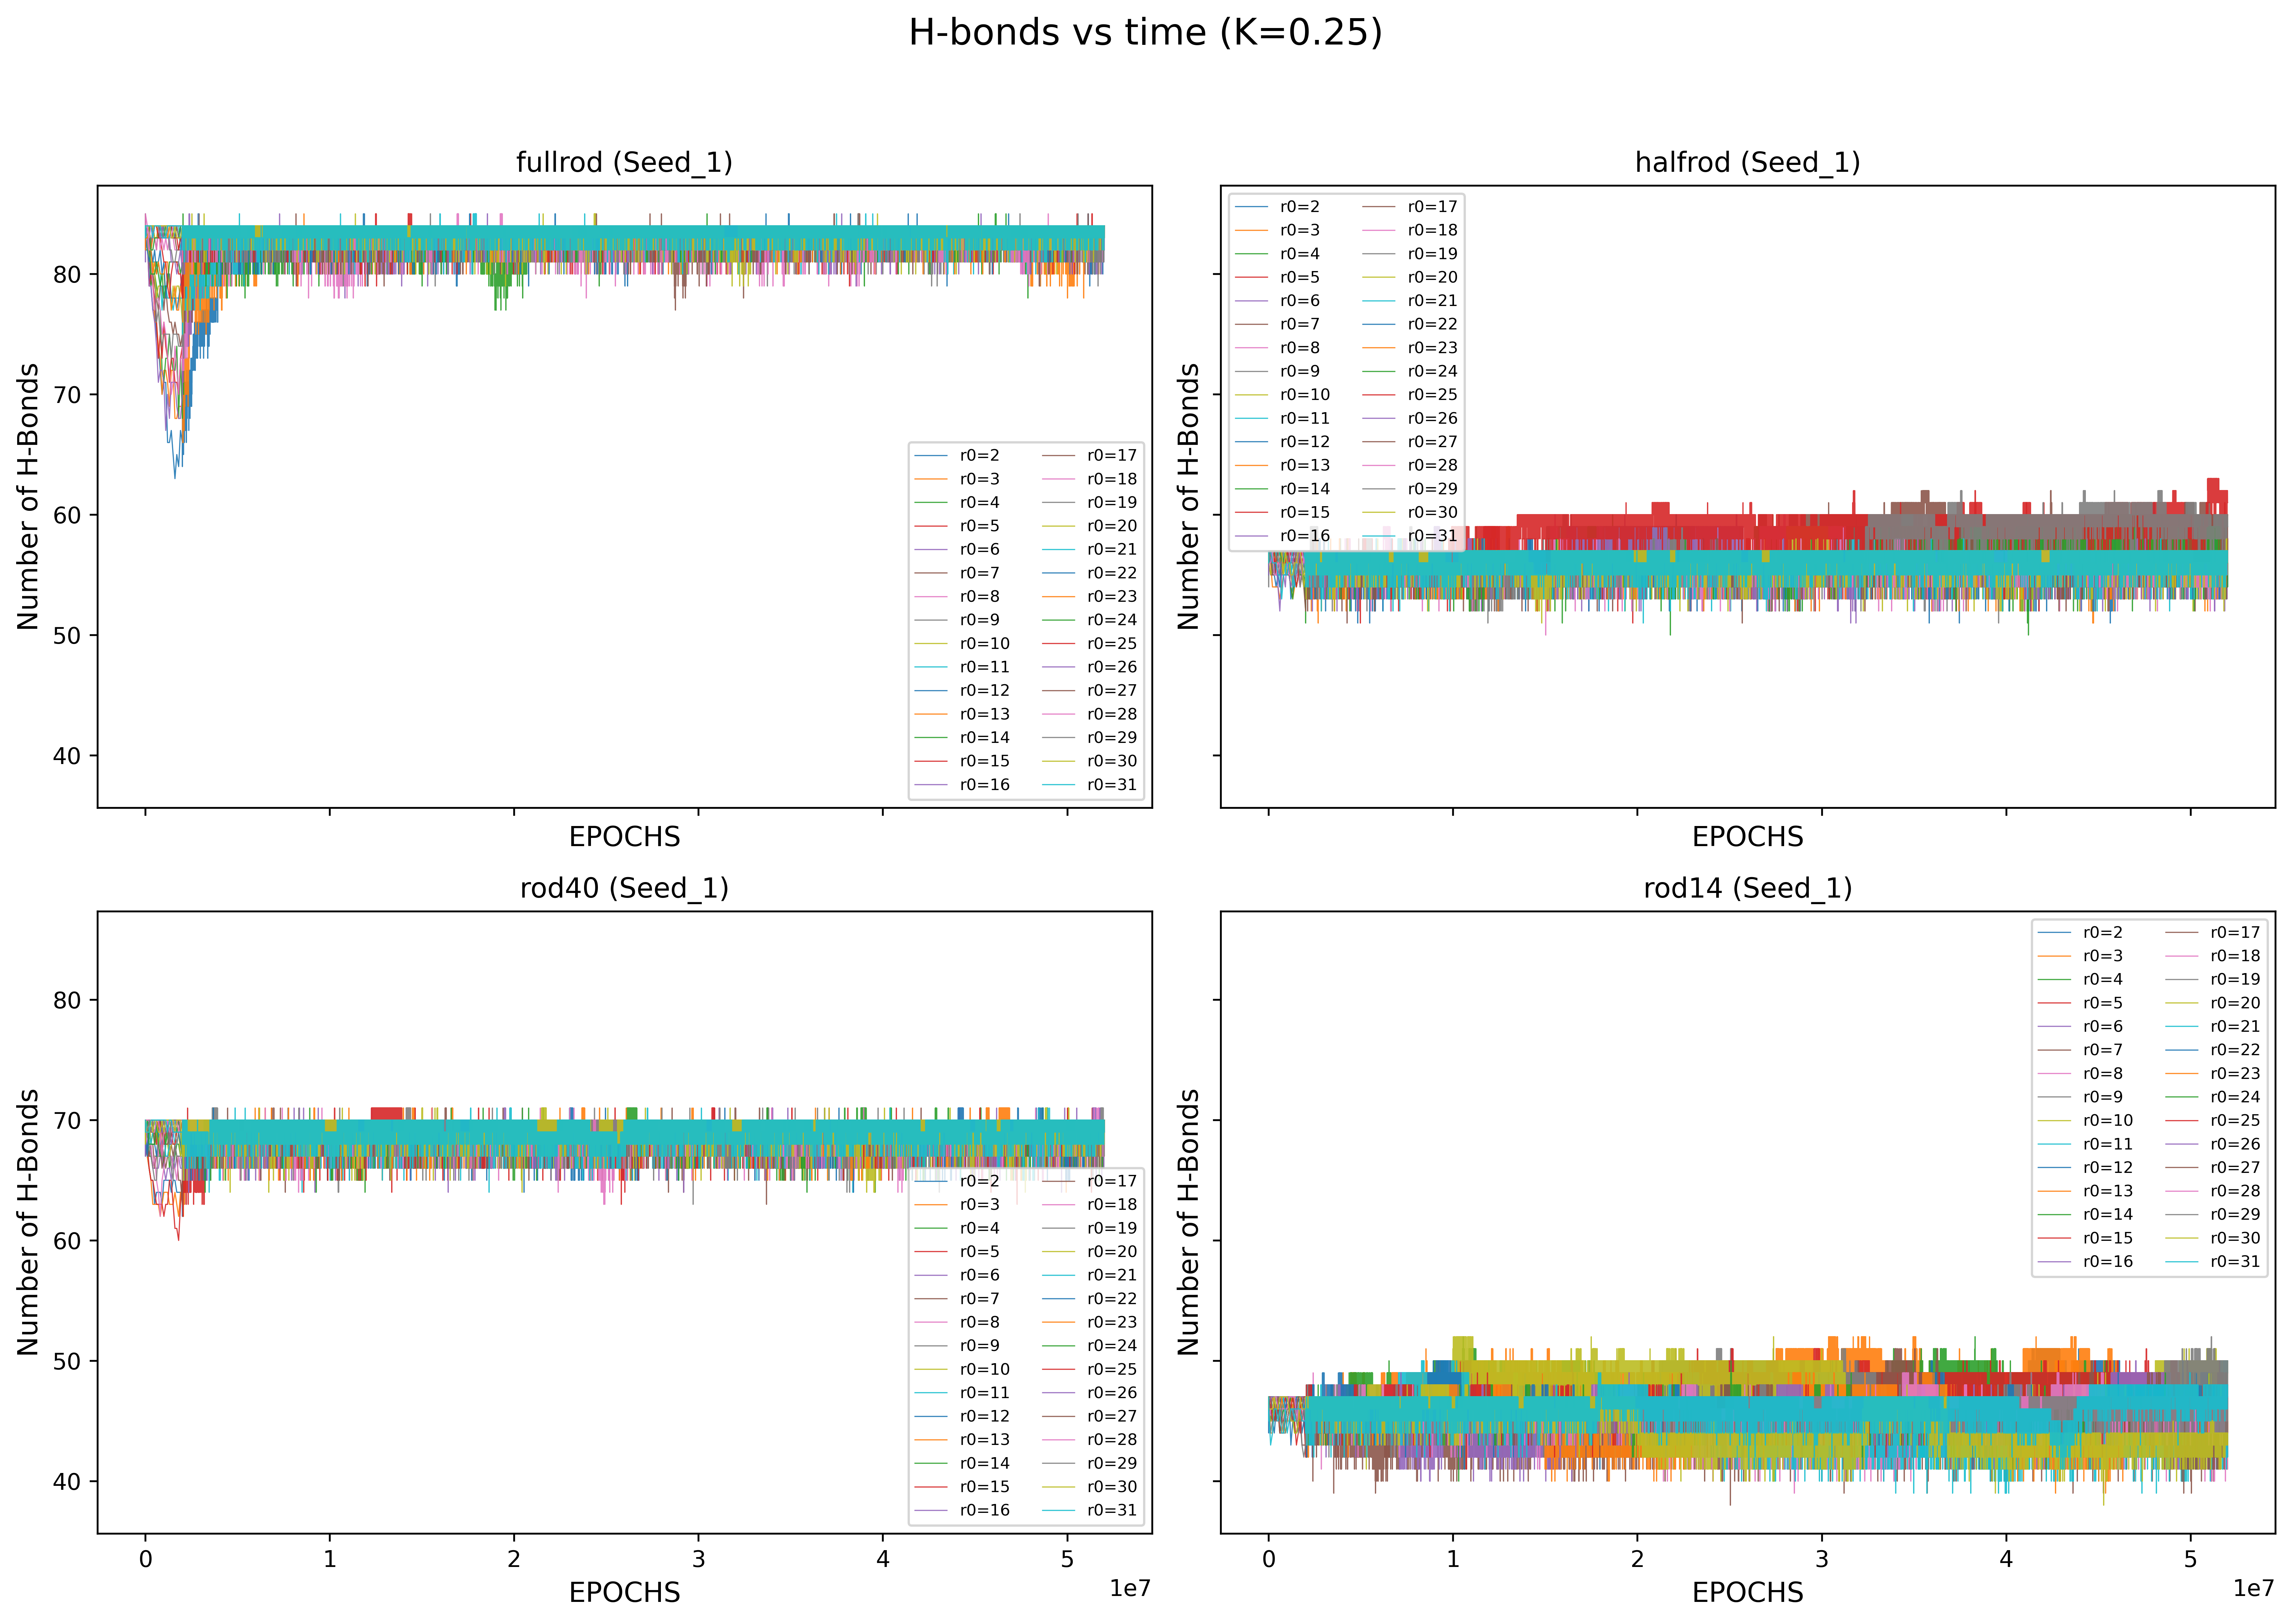

In [3]:
import matplotlib.pyplot as plt

# --- controls ---
r0_values = [2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31]
k_values  = [0.25]

rod_types = ["fullrod", "halfrod", "rod40", "rod14"]  
seed_to_plot = 1  # plot only Seed_1 for now


for k in k_values:
    fig, axes = plt.subplots(
        nrows=2, ncols=2,
        figsize=(14, 10),
        dpi=500,
        sharex=True, sharey=True
    )
    axes = axes.ravel()

    for ax, rod_type in zip(axes, rod_types):
        # guardrails for missing rod/seed/k
        if rod_type not in dfs_dist:
            ax.set_title(f"{rod_type} (missing)")
            ax.axis("off")
            continue
        if seed_to_plot not in dfs_dist[rod_type]:
            ax.set_title(f"{rod_type} Seed_{seed_to_plot} (missing)")
            ax.axis("off")
            continue
        if k not in dfs_dist[rod_type][seed_to_plot]:
            ax.set_title(f"{rod_type} K={k} (missing)")
            ax.axis("off")
            continue

        for r0 in r0_values:
            if r0 not in dfs_dist[rod_type][seed_to_plot][k]:
                continue
            df = dfs_dist[rod_type][seed_to_plot][k][r0]

            ax.plot(
                df["step"], df["hbond"],
                alpha=0.9, linewidth=0.5,
                label=f"r0={r0}"
            )

        ax.set_title(f"{rod_type} (Seed_{seed_to_plot})", fontsize=12)
        ax.set_xlabel("EPOCHS", fontsize=12)
        ax.set_ylabel("Number of H-Bonds", fontsize=12)

        # legends get huge; keep tiny or comment out
        ax.legend(fontsize=7, ncol=2, frameon=True)

    fig.suptitle(f"H-bonds vs time (K={k})", fontsize=16)
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

In [4]:
# DEFINE CUTOFF VALUE BASED ON HBOND PLOTS
CUTOFF = 1.5e7

# Cutoff-filtered versions:
# dfs_dist_cfiltered[rod_type][seed][k][r0] = df filtered by step >= CUTOFF
# dfs_cxstck_cfiltered["fullrod"][seed][k][r0] = df filtered by step >= CUTOFF (if present)

dfs_dist_cfiltered = {}
dfs_cxstck_cfiltered = {}

for rod_type, by_seed in dfs_dist.items():
    dfs_dist_cfiltered[rod_type] = {}
    for seed, by_k in by_seed.items():
        dfs_dist_cfiltered[rod_type][seed] = {}
        for k, by_r0 in by_k.items():
            dfs_dist_cfiltered[rod_type][seed][k] = {}
            for r0, df in by_r0.items():
                dfs_dist_cfiltered[rod_type][seed][k][r0] = (
                    df[df["step"] >= CUTOFF].reset_index(drop=True)
                )

# cxstck is only for fullrod, so filter if it exists
if "fullrod" in dfs_cxstck:
    dfs_cxstck_cfiltered["fullrod"] = {}
    for seed, by_k in dfs_cxstck["fullrod"].items():
        dfs_cxstck_cfiltered["fullrod"][seed] = {}
        for k, by_r0 in by_k.items():
            dfs_cxstck_cfiltered["fullrod"][seed][k] = {}
            for r0, df in by_r0.items():
                dfs_cxstck_cfiltered["fullrod"][seed][k][r0] = (
                    df[df["step"] >= CUTOFF].reset_index(drop=True)
                )

In [5]:
import numpy as np
import pandas as pd

# r0: 2..31 step 1
r0_values = list(range(2, 32))

# Expects:
# dfs_dist_cfiltered[rod_type][seed][k][r0] -> df with columns:
# ["step","dist","force_mag","hbond","force_energy"]

# -----------------------
# 1) per-seed steady-state stats (one row per rod_type/seed/k/r0)
#    extension = dist (as you said)
#    force     = signed force exactly like your original code
# -----------------------
stats_rows = []

for rod_type, by_seed in dfs_dist_cfiltered.items():
    for seed, by_k in by_seed.items():
        for k, by_r0 in by_k.items():
            for r0 in r0_values:
                df = by_r0.get(r0)
                if df is None or df.empty:
                    continue

                # signed force: +|F| if dist > r0, -|F| if dist < r0
                signed_force = np.sign(df["dist"].to_numpy() - r0) * df["force_mag"].to_numpy()

                stats_rows.append({
                    "rod_type": rod_type,
                    "seed": seed,
                    "k": k,
                    "r0": float(r0),

                    "F_mean": signed_force.mean(),
                    "F_std_time": signed_force.std(ddof=0),

                    "dist_mean": df["dist"].mean(),
                    "dist_std_time": df["dist"].std(ddof=0),

                    "|F|_mean": df["force_mag"].mean(),
                    "|F|_std_time": df["force_mag"].std(ddof=0),

                    "force_energy_mean": df["force_energy"].mean(),
                    "force_energy_std_time": df["force_energy"].std(ddof=0),

                    "hbonds_mean": df["hbond"].mean(),
                    "hbonds_std_time": df["hbond"].std(ddof=0),

                    "n_frames": len(df),
                })

stats_df = (
    pd.DataFrame(stats_rows)
    .sort_values(["rod_type", "seed", "k", "r0"])
    .reset_index(drop=True)
)

# -----------------------
# 2) aggregate across seeds for plotting mean signed force vs mean dist
#    error bars = 2 * SD across seeds (not time-series SD)
# -----------------------
plot_df = (
    stats_df
    .groupby(["rod_type", "k", "r0"], as_index=False)
    .agg(
        dist_mean_avg=("dist_mean", "mean"),
        dist_mean_sd=("dist_mean", "std"),  # across seeds
        F_mean_avg=("F_mean", "mean"),
        F_mean_sd=("F_mean", "std"),        # across seeds
        n_seeds=("seed", "nunique"),
    )
)

# if only 1 seed in a group => std = NaN; set to 0 for clean error bars
plot_df[["dist_mean_sd", "F_mean_sd"]] = plot_df[["dist_mean_sd", "F_mean_sd"]].fillna(0.0)

# 2-sigma error bars (across seeds)
plot_df["xerr_2sd"] = 2.0 * plot_df["dist_mean_sd"]
plot_df["yerr_2sd"] = 2.0 * plot_df["F_mean_sd"]

plot_df = plot_df.sort_values(["rod_type", "k", "r0"]).reset_index(drop=True)

print("Per-seed stats (head):")
print(stats_df.head())

print("\nSeed-aggregated data for errorbar plots (head):")
print(plot_df.head())

Per-seed stats (head):
  rod_type  seed     k   r0    F_mean  F_std_time  dist_mean  dist_std_time  \
0  fullrod     1  0.25  2.0  0.145885    0.137333   2.583540       0.549331   
1  fullrod     1  0.25  3.0  0.114015    0.147850   3.456058       0.591401   
2  fullrod     1  0.25  4.0  0.101766    0.153856   4.407065       0.615423   
3  fullrod     1  0.25  5.0  0.090254    0.152815   5.361017       0.611261   
4  fullrod     1  0.25  6.0  0.083462    0.156743   6.333847       0.626972   

   |F|_mean  |F|_std_time  force_energy_mean  force_energy_std_time  \
0  0.164615      0.114213           0.000945               0.001184   
1  0.150661      0.110274           0.000820               0.001105   
2  0.148911      0.108873           0.000801               0.001074   
3  0.143115      0.104959           0.000741               0.000991   
4  0.142508      0.105951           0.000742               0.001016   

   hbonds_mean  hbonds_std_time  n_frames  
0    83.672153         0.578049

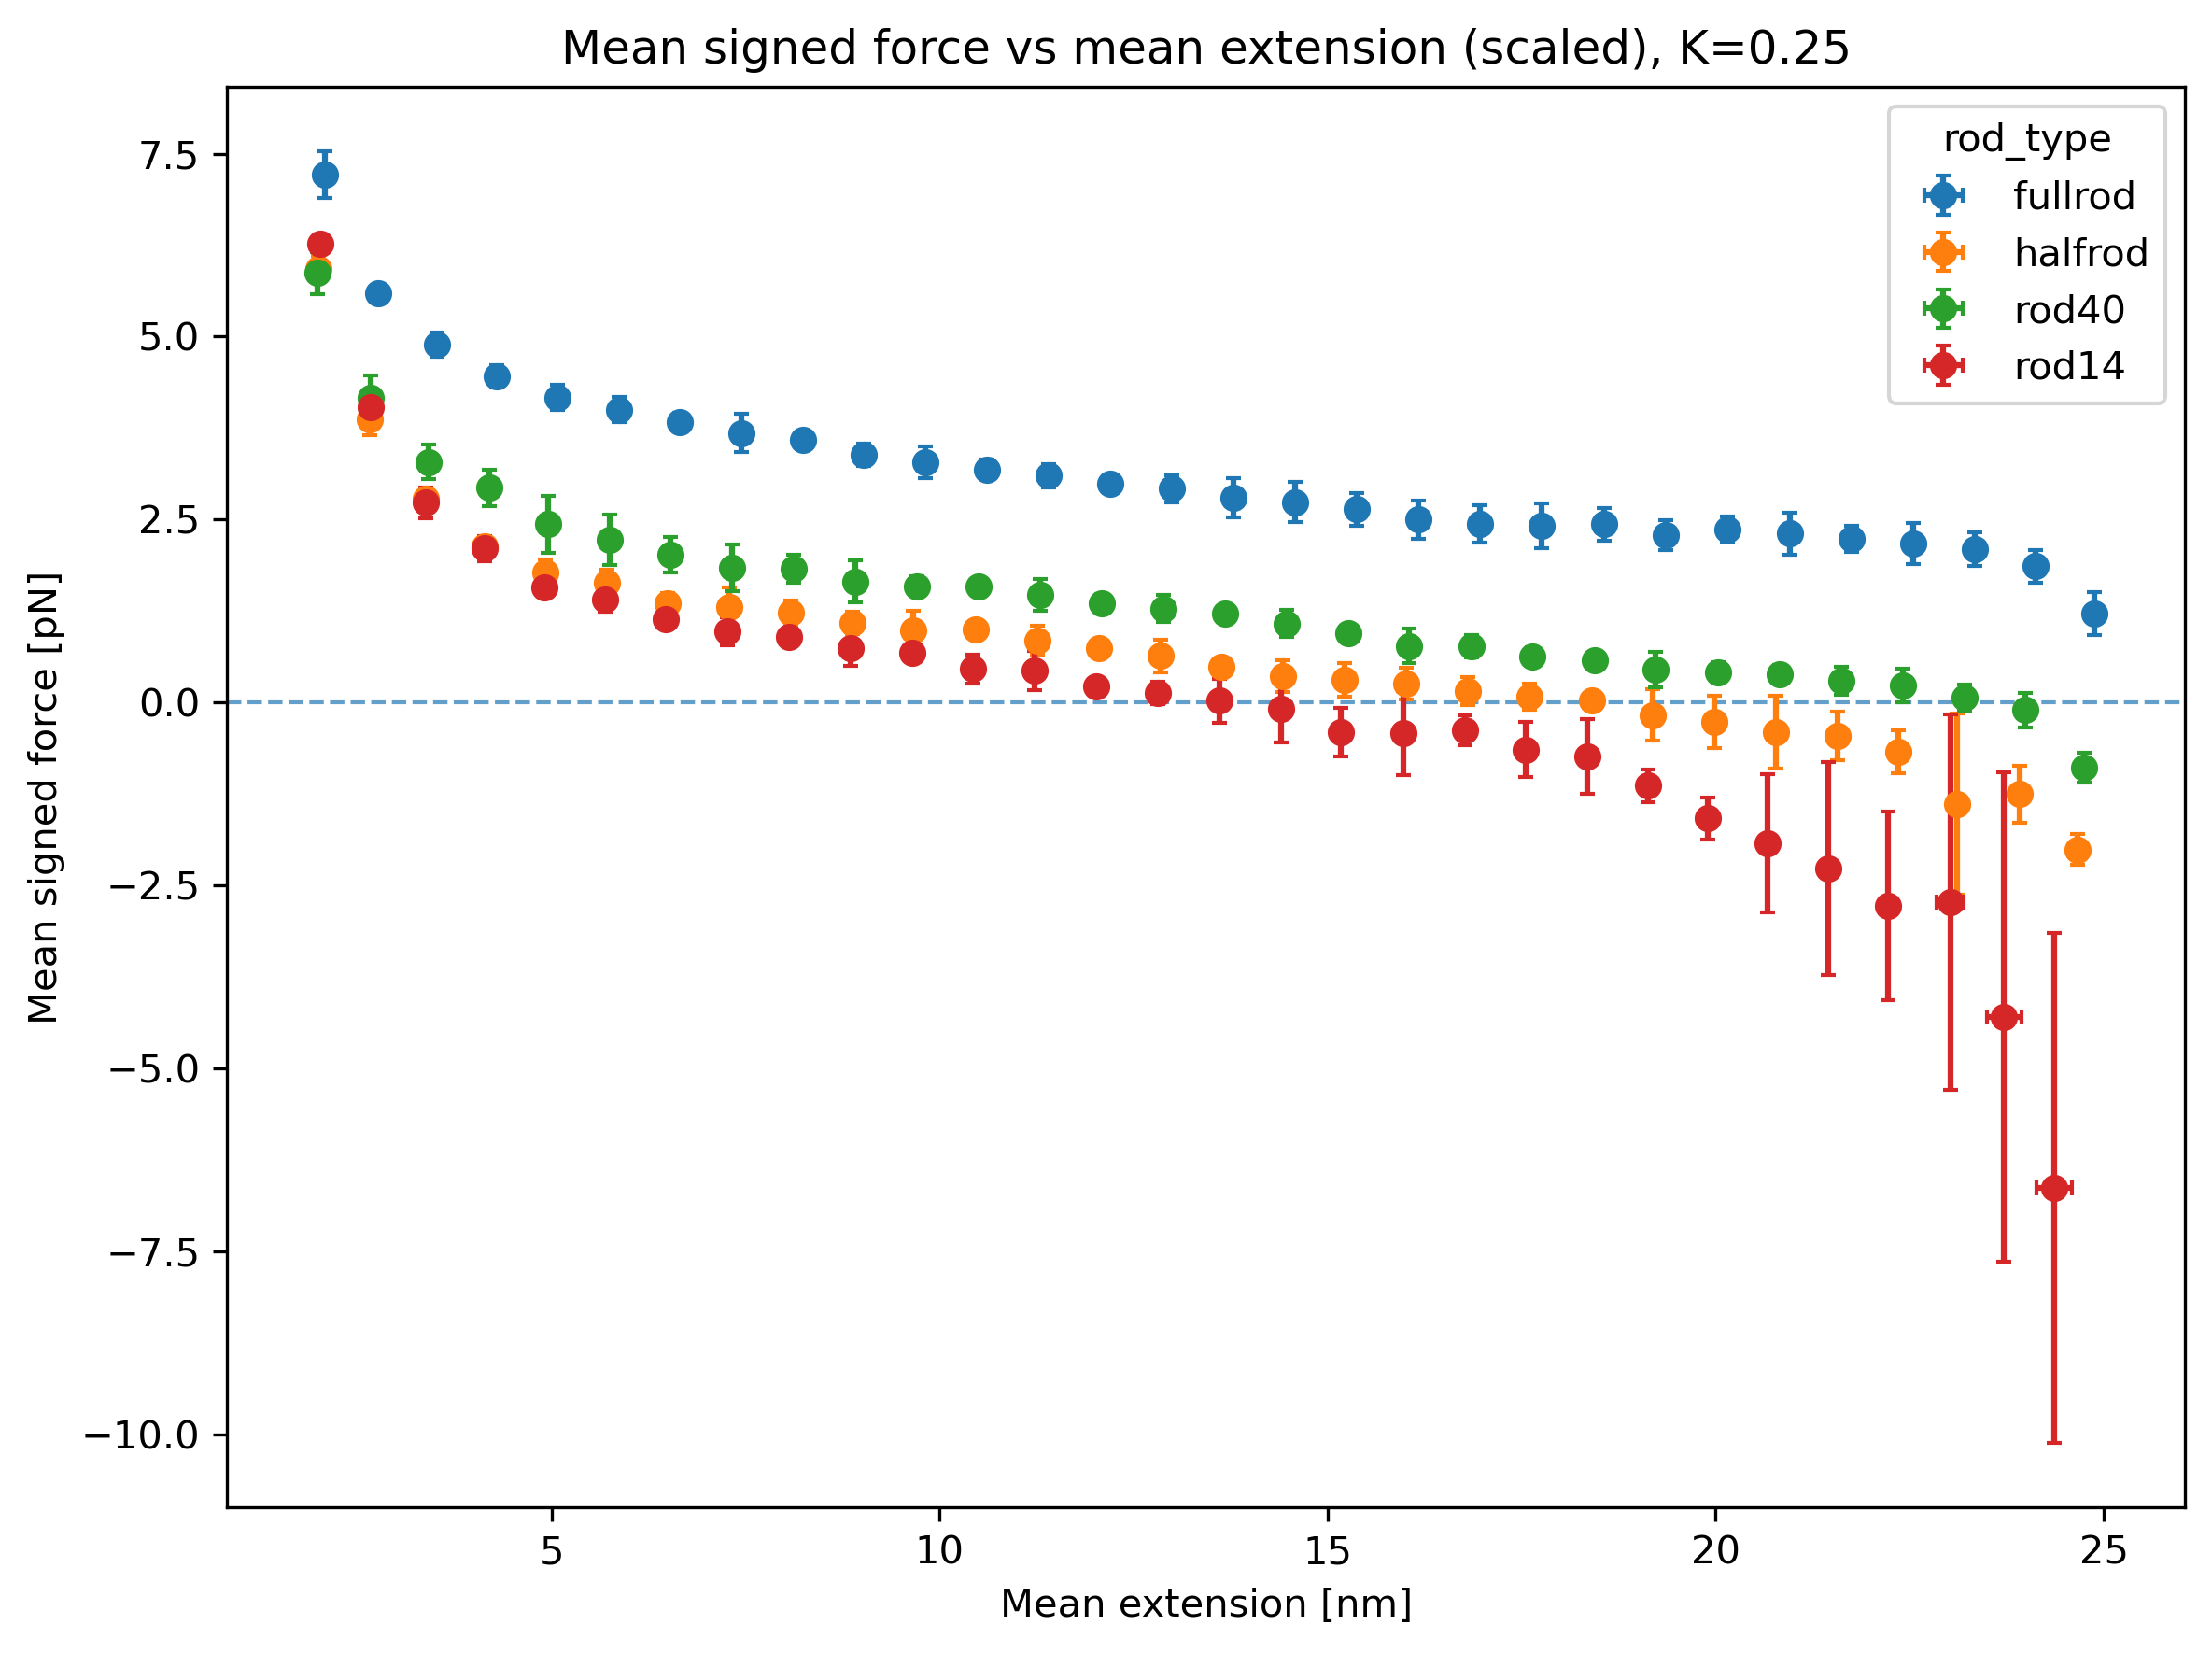

In [11]:
import matplotlib.pyplot as plt

rod_order = ["fullrod", "halfrod", "rod40", "rod14"]
k_order   = sorted(plot_df["k"].unique())

FORCE_SCALE = 48.6
EXT_SCALE   = 0.8

for k in k_order:
    fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

    # y=0 line (force axis) — stays at 0 after scaling
    ax.axhline(0, linestyle="--", linewidth=1, alpha=0.7)

    for rod_type in rod_order:
        g = (plot_df[(plot_df["k"] == k) & (plot_df["rod_type"] == rod_type)]
             .sort_values("r0"))
        if g.empty:
            continue

        x    = g["dist_mean_avg"] * EXT_SCALE
        y    = g["F_mean_avg"]    * FORCE_SCALE
        xerr = g["xerr_2sd"]      * EXT_SCALE
        yerr = g["yerr_2sd"]      * FORCE_SCALE

        ax.errorbar(
            x, y,
            xerr=xerr, yerr=yerr,
            fmt="o", capsize=2,
            label=rod_type
        )

    ax.set_title(f"Mean signed force vs mean extension (scaled), K={k}")
    ax.set_xlabel("Mean extension [nm]")
    ax.set_ylabel("Mean signed force [pN]")
    ax.legend(title="rod_type", frameon=True)
    fig.tight_layout()
    plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# r0: 2..31
r0_values = list(range(2, 32))
seeds = range(1, 6)

# Choose which K to plot (or loop over k_values like before)
k_values_to_plot = sorted(dfs_cxstck_cfiltered.get("fullrod", {}).get(1, {}).keys())  # auto from data
# or hardcode, e.g.:
k_values_to_plot = [0.25]

# Define what “cxstack = 0” means (exact 0 vs near-0 tolerance)
ZERO_TOL = 1e-6  # set e.g. 1e-6 if values are floating noise around 0

def frac_zero(x: np.ndarray, tol: float = 0.0) -> float:
    x = np.asarray(x, dtype=float)
    if tol == 0.0:
        return float(np.mean(x == 0.0))
    return float(np.mean(np.abs(x) <= tol))

# Columns in obs_cxstck:
# ["step", "cxstck_31_32", "cxstck_0_85"]
pair_cols = ["cxstck_31_32", "cxstck_0_85"]

for k in k_values_to_plot:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=300, sharey=True)

    for ax, col in zip(axes, pair_cols):
        for seed in seeds:
            # guard for missing seed/k
            if "fullrod" not in dfs_cxstck_cfiltered:
                continue
            if seed not in dfs_cxstck_cfiltered["fullrod"]:
                continue
            if k not in dfs_cxstck_cfiltered["fullrod"][seed]:
                continue

            xs, ys = [], []
            for r0 in r0_values:
                df = dfs_cxstck_cfiltered["fullrod"][seed][k].get(r0)
                if df is None or df.empty or col not in df.columns:
                    continue

                xs.append(r0)
                ys.append(frac_zero(df[col].to_numpy(), tol=ZERO_TOL))

            # 5 points per r0 (one per seed), just opacity
            ax.scatter(xs, ys, alpha=0.35, s=18, label=f"Seed_{seed}")

        ax.set_title(col)
        ax.set_xlabel("r0")
        ax.set_ylabel("Frequency(cxstck = 0)")

    fig.suptitle(f"Fullrod: frequency of cxstck==0 vs r0 (K={k}, cutoff applied)", fontsize=13)
    # legend can get busy;
    #axes[1].legend(fontsize=8, frameon=True, loc="best")
    fig.tight_layout(rect=[0, 0, 1, 0.9])
    plt.show()